## ISOM4030 Lab 3 - Summary and Visualization of Gradient Descent

In [ ]:
# If you want to enable matplotlib's interactive features
# install jupyter-matplotlib (a.k.a. ipympl) via pip or conda.
! pip install ipympl --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.6/511.6 kB 7.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 61.2 MB/s eta 0:00:00


Restart runtime to continue

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

# Enable the `widget` backend.

%matplotlib widget

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.style.use('seaborn-white')

import pandas as pd
import numpy as np

from lab3_utils import plt_stationary, plt_update_onclick, plt_gradient_descent_path

%config InlineBackend.figure_format="retina"

<ipython-input-3-2cc583024192>:4: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


In [ ]:
# extract 6 pairs of data from the housing prices dataset
# x_train is storing values of house size (1000 sqrft)
# y_train is storing values of house price (in thousands of dollars)

x_train = np.array([1.0, 1.7, 2.0, 2.5, 3.0, 3.2])
y_train = np.array([250, 300, 480, 430, 630, 730])

## 3D Cost Function Visualization


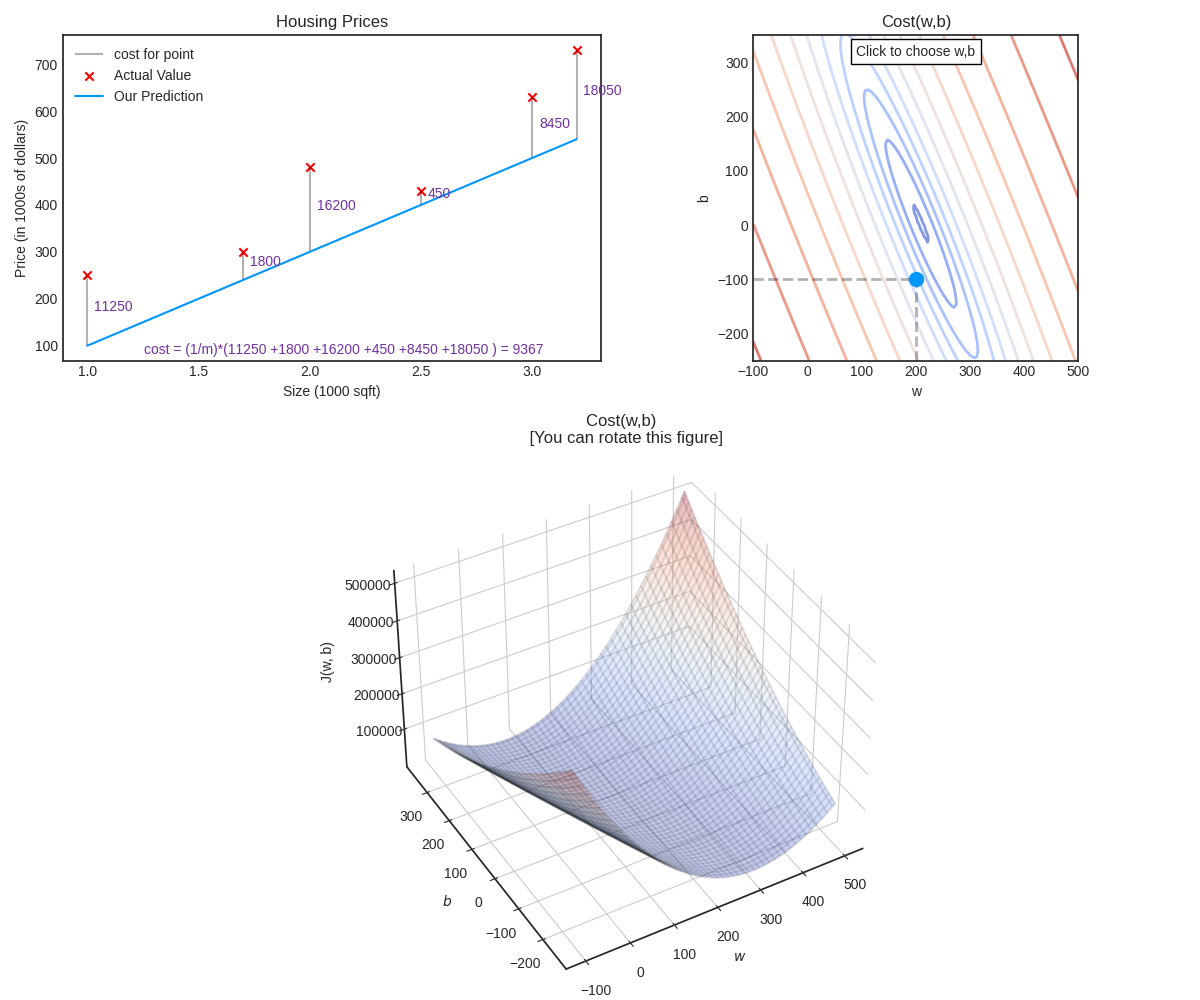

In [ ]:
plt.close('all')
fig, ax, dyn_items = plt_stationary(x_train, y_train)
updater = plt_update_onclick(fig, ax, x_train, y_train, dyn_items)

In [ ]:
# gradient descent function - inputs:
# g (input function), alpha (steplength parameter), max_its (maximum number of iterations),

def gradient_descent(x_train, y_train, init_parameters, lr, n_iterations):

  b, w = init_parameters
  weight_history = []; cost_history = []

  for epoch in range(n_iterations):

      # Your code starts here

      weight_history.append((b, w))
      yhat = w * x_train + b
      error = yhat - y_train
      b_grad = error.mean()
      w_grad = (x_train * error).mean()
      b = b - lr * b_grad
      w = w - lr * w_grad
      cost_history.append((error ** 2).mean() / 2)

      # Your code ends here

  return weight_history, cost_history

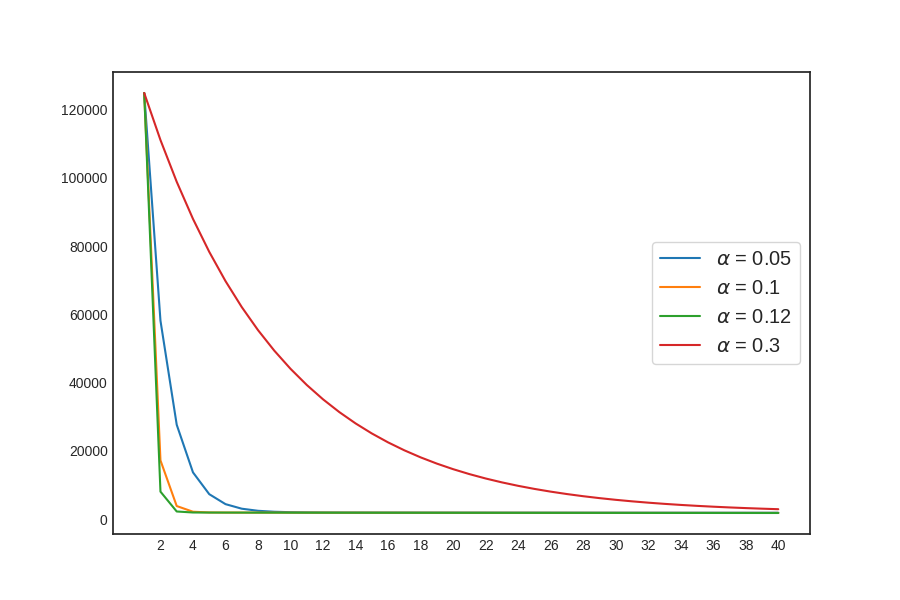

In [ ]:
n_iterations = 40

fig, ax = plt.subplots(1, 1, figsize=(9, 6))

for alpha in [0.05, 0.1, 0.12, 0.3]:
  weight_history, cost_history = gradient_descent(x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  ax.plot(np.arange(1, 41), cost_history, label=r"$\alpha$" + f" = {alpha}")

ax.legend(loc="center right", fontsize="x-large", frameon=True)

ax.set(xticks=range(2, 41, 2))
plt.show()

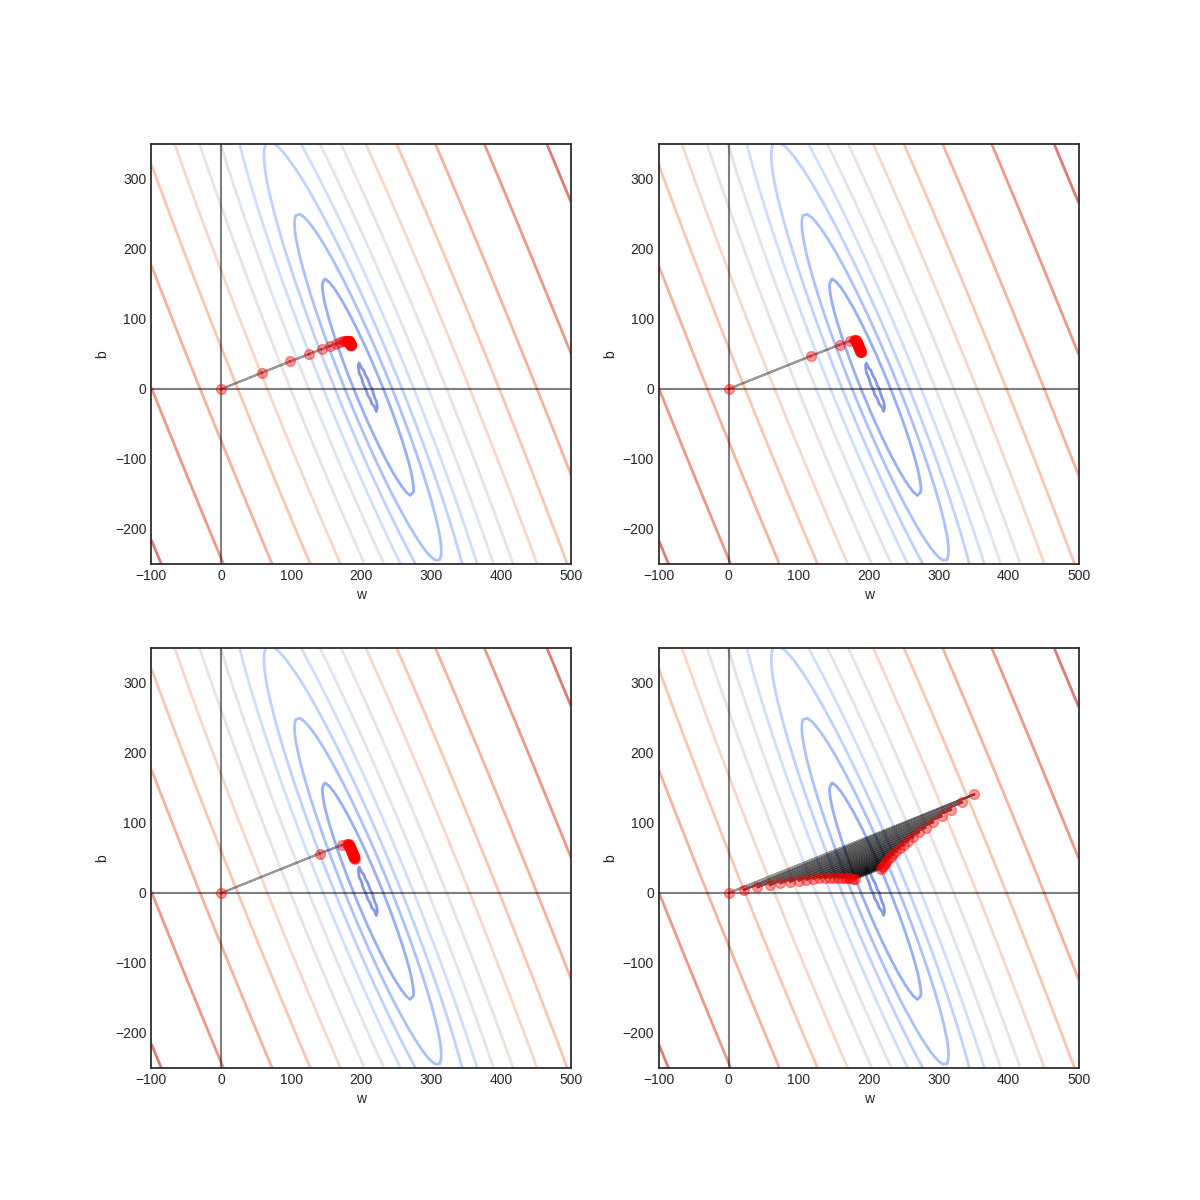

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 12))
w_range = np.array([200-300, 200+300])
b_range = np.array([50-300, 50+300])

for ax, alpha in zip(ax.flat, [0.05, 0.1, 0.12, 0.3]):
  weight_history, cost_history = gradient_descent(x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  plt_gradient_descent_path(fig, ax, x_train, y_train, weight_history, w_range, b_range)

## Feature Scaling


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression


scaler = StandardScaler()
x_tmp = x_train.reshape(-1, 1)    # fit() takes a 2-D array as argument
scaler.fit(x_tmp)
scaled_x_train = scaler.transform(x_tmp).flatten()

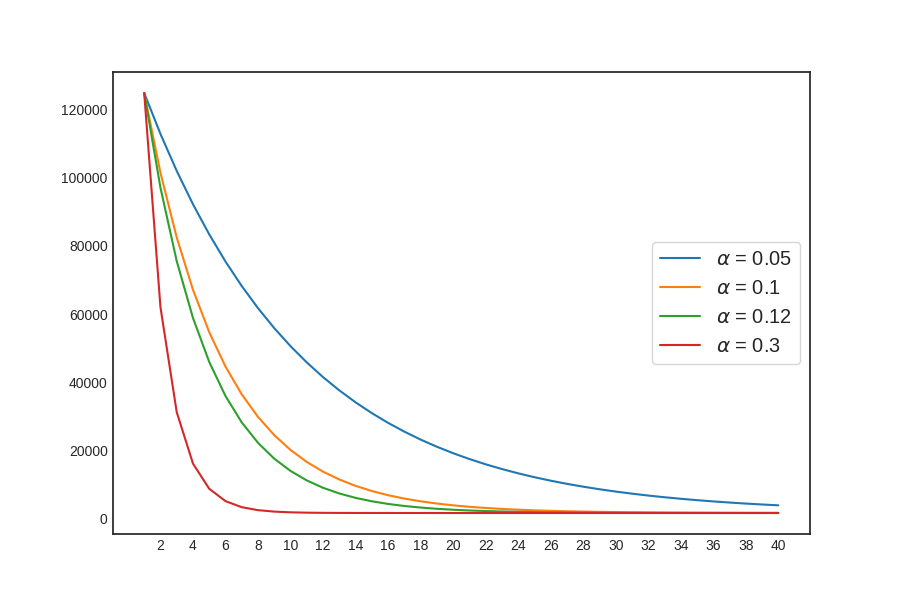

In [ ]:
n_iterations = 40
fig, ax = plt.subplots(1, 1, figsize=(9, 6))

for alpha in [0.05, 0.1, 0.12, 0.3]:
  weight_history, cost_history = gradient_descent(scaled_x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  ax.plot(np.arange(1, 41), cost_history, label=r"$\alpha$" + f" = {alpha}")

ax.legend(loc="center right", fontsize="x-large", frameon=True)

ax.set(xticks=range(2, 41, 2))
plt.show()

In [ ]:
lm = LinearRegression()
lm.fit(scaled_x_train.reshape(-1, 1), y_train)
lm.intercept_, lm.coef_[0]

(469.99999999999994, 158.83398122169453)

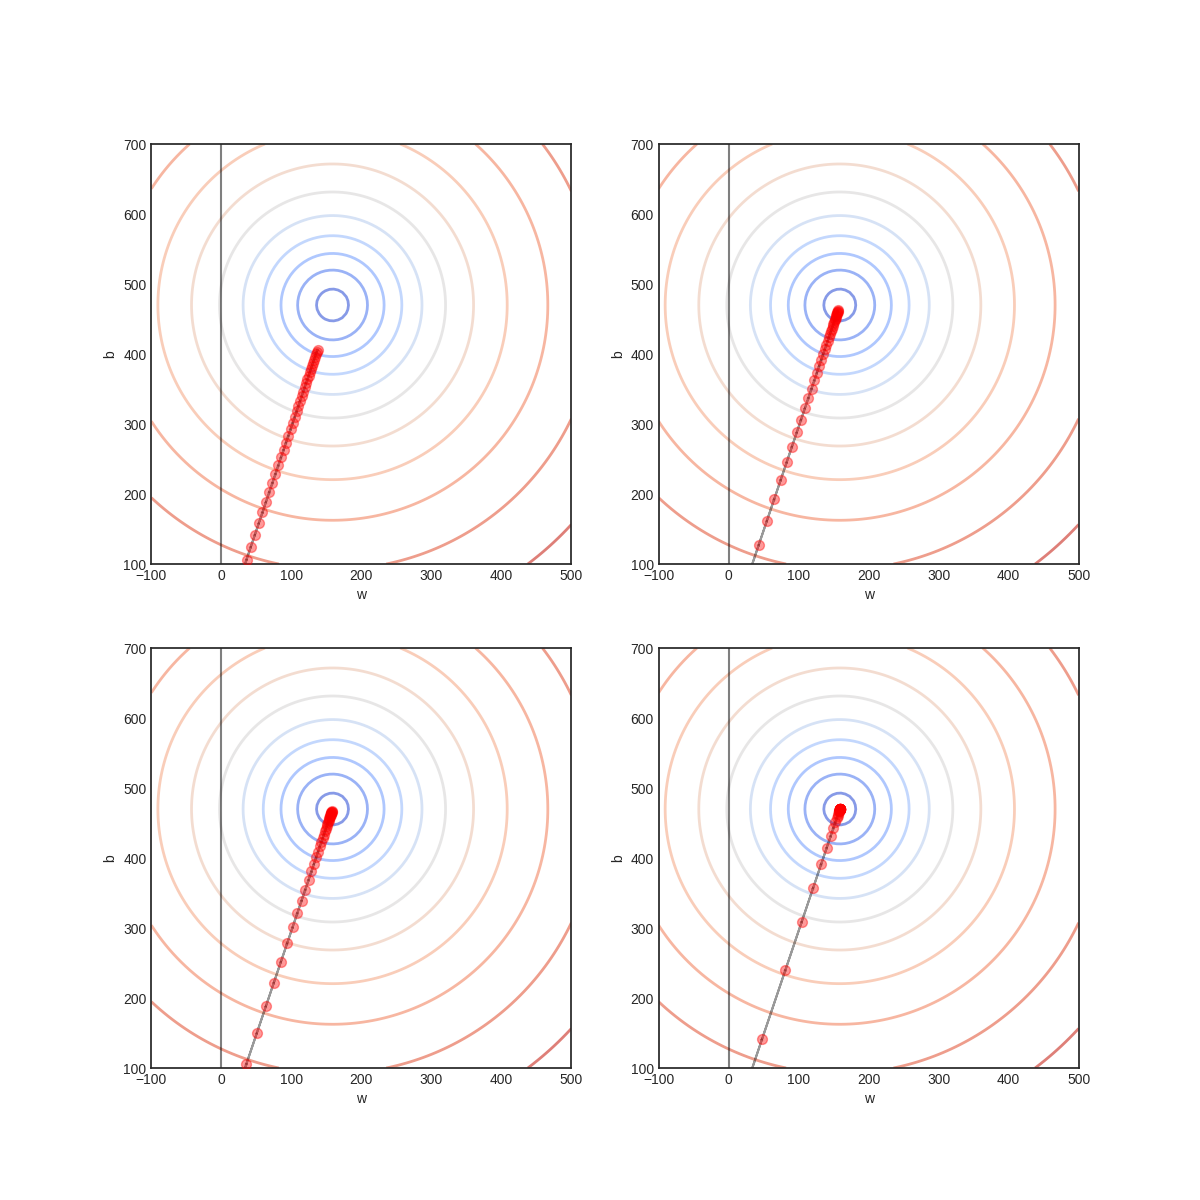

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 12))
w_range = np.array([200-300, 200+300])
b_range = np.array([400-300, 400+300])

# Your code starts here

for ax, alpha in zip(ax.flat, [0.05, 0.1, 0.12, 0.3]):
  weight_history, cost_history = gradient_descent(scaled_x_train, y_train, np.array([0, 0]), alpha, n_iterations)
  plt_gradient_descent_path(fig, ax, scaled_x_train, y_train, weight_history, w_range, b_range)


In [ ]:
x = np.array([1.0, 1.7, 2.0, 2.5, 3.0, 3.2])
y = np.array([250, 300, 480, 430, 630, 730])

w,b,lr = 0,0,0.1

n_iterations = 100

yhat = x * w + b
error = yhat - y
w_grad = (x * error).mean()
b_grad = error.mean()
# equivalently, np.square(error).mean() / 2
Loss = (error ** 2).mean() / 2

for epoch in range(n_iterations):
  # Step 1 - Compute model's predicted output
  yhat = w * x + b
  # Step 2 - Compute the loss using all data points
  # Compute individual errors
  error = yhat - y
  # Compute mean squared error (MSE)
  loss = (error ** 2).mean() / 2
  # Step 3 - Compute gradients for both parameters
  b_grad = error.mean()
  w_grad = (x * error).mean()
  # Step 4 - Update parameters
  b = b - lr * b_grad
  w = w - lr * w_grad
print(b, w)

31.55401925691066 197.47864904161335
